In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv('../data/real_estate_cleaned.csv')
df.head()

,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,yr_renovated,street,city,zipcode,house_age,price_per_sqft,city_avg_price_per_sqft,ratio_to_city_avg,was_renovated,has_basement
0,2014-05-02,313000.0,3.0,1.50,1340,7912,1.5,0,0,3,...,2005,18810 Densmore Ave N,Shoreline,98133,59,233.582090,245.906375,0.949882,1,0
1,2014-05-02,2384000.0,5.0,2.50,3650,9050,2.0,0,4,5,...,0,709 W Blaine St,Seattle,98119,93,653.150685,326.397539,2.001089,0,1
2,2014-05-02,342000.0,3.0,2.00,1930,11947,1.0,0,0,4,...,0,26206-26214 143rd Ave SE,Kent,98042,48,177.202073,276.574038,0.640704,0,0
3,2014-05-02,420000.0,3.0,2.25,2000,8030,1.0,0,0,4,...,0,857 170th Pl NE,Bellevue,98008,51,210.000000,323.754916,0.648639,0,1
4,2014-05-02,550000.0,4.0,2.50,1940,10500,1.0,0,0,4,...,1992,9105 170th Ave NE,Redmond,98052,38,283.505155,278.775040,1.016967,1,1


#Build a Typical Property Profile

In [4]:
mean_price = df["price"].mean()
median_price = df["price"].median()

print(f"Mean Price: ${mean_price:,.2f}")
print(f"Median Price: ${median_price:,.2f}")

Mean Price: $548,858.19
Median Price: $465,000.00


In [5]:
living_mean = df["sqft_living"].mean()
living_median = df["sqft_living"].median()

lot_mean = df["sqft_lot"].mean()
lot_median = df["sqft_lot"].median()

print(f"Average Living Area: {living_mean:,.2f} sqft")
print(f"Median Living Area: {living_median:,.2f} sqft")

print(f"\nAverage Lot Size: {lot_mean:,.2f} sqft")
print(f"Median Lot Size: {lot_median:,.2f} sqft")

Average Living Area: 2,131.24 sqft
Median Living Area: 1,970.00 sqft

Average Lot Size: 14,839.41 sqft
Median Lot Size: 7,679.00 sqft


In [6]:
typical_bedrooms = df["bedrooms"].mode()[0]
typical_bathrooms = df["bathrooms"].mode()[0]
typical_floors = df["floors"].mode()[0]

print(f"Most Common Bedrooms: {typical_bedrooms}")
print(f"Most Common Bathrooms: {typical_bathrooms}")
print(f"Most Common Floors: {typical_floors}")

Most Common Bedrooms: 3.0
Most Common Bathrooms: 2.5
Most Common Floors: 1.0


In [7]:
mean_age = df["house_age"].mean()
median_age = df["house_age"].median()

print(f"Average House Age: {mean_age:.1f} years")
print(f"Median House Age: {median_age:.1f} years")

Average House Age: 43.2 years
Median House Age: 38.0 years


In [8]:
common_condition = df["condition"].mode()[0]

print(f"Most Common Condition: {common_condition}")

Most Common Condition: 3


In [9]:
df["condition"].value_counts().sort_index()

condition
1       5
2      31
3    2846
4    1234
5     425
Name: count, dtype: int64

In [10]:
basement_pct = df["has_basement"].mean() * 100
renovated_pct = df["was_renovated"].mean() * 100
waterfront_pct = df["waterfront"].mean() * 100

print(f"Properties with Basement: {basement_pct:.2f}%")
print(f"Renovated Properties: {renovated_pct:.2f}%")
print(f"Waterfront Properties: {waterfront_pct:.2f}%")

Properties with Basement: 40.28%
Renovated Properties: 40.48%
Waterfront Properties: 0.66%


In [11]:
print(
    f"A typical property in the dataset has a median price of ${median_price:,.0f}, "
    f"with around {living_median:,.0f} sqft of living space and a lot size of approximately "
    f"{lot_median:,.0f} sqft. The most common property has around "
    f"{typical_bedrooms:g} bedrooms, {typical_bathrooms:g} bathrooms, and "
    f"{typical_floors:g} floor(s). The median house age is approximately "
    f"{median_age:.0f} years, while the most common condition rating is {common_condition}. "
    f"About {basement_pct:.1f}% of properties have a basement, "
    f"{renovated_pct:.1f}% have been renovated, and only "
    f"{waterfront_pct:.1f}% are waterfront properties."
)

A typical property in the dataset has a median price of $465,000, with around 1,970 sqft of living space and a lot size of approximately 7,679 sqft. The most common property has around 3 bedrooms, 2.5 bathrooms, and 1 floor(s). The median house age is approximately 38 years, while the most common condition rating is 3. About 40.3% of properties have a basement, 40.5% have been renovated, and only 0.7% are waterfront properties.


# Analyze Price Distribution

In [12]:
price_stats = df["price"].describe()
price_stats

count    4.541000e+03
mean     5.488582e+05
std      3.665229e+05
min      8.000000e+04
25%      3.265000e+05
50%      4.650000e+05
75%      6.570000e+05
max      7.062500e+06
Name: price, dtype: float64

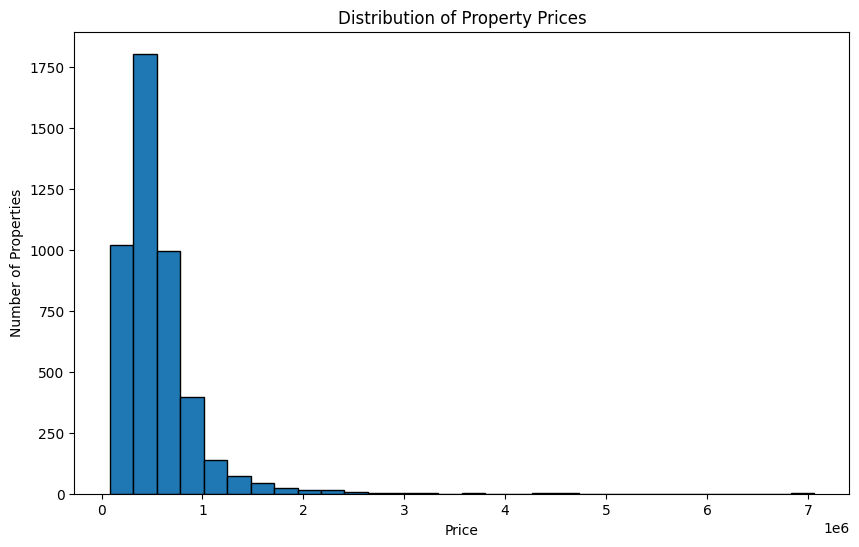

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.hist(df["price"], bins=30, edgecolor="black")

plt.title("Distribution of Property Prices")
plt.xlabel("Price")
plt.ylabel("Number of Properties")

plt.show()

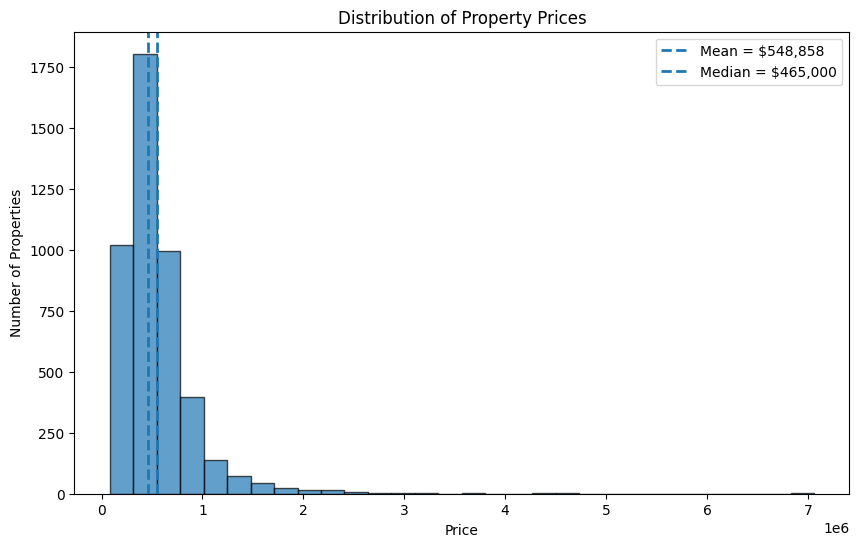

In [14]:
plt.figure(figsize=(10, 6))

plt.hist(df["price"], bins=30, edgecolor="black", alpha=0.7)

plt.axvline(mean_price, linestyle="--", linewidth=2,
            label=f"Mean = ${mean_price:,.0f}")

plt.axvline(median_price, linestyle="--", linewidth=2,
            label=f"Median = ${median_price:,.0f}")

plt.title("Distribution of Property Prices")
plt.xlabel("Price")
plt.ylabel("Number of Properties")
plt.legend()

plt.show()


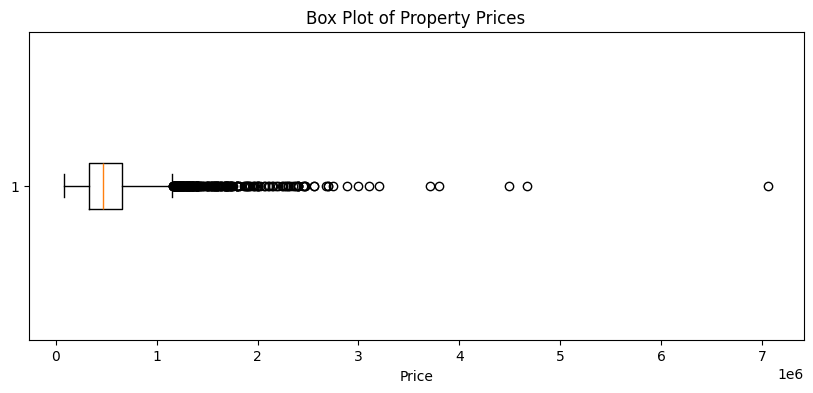

In [15]:
plt.figure(figsize=(10, 4))

plt.boxplot(df["price"], vert=False)

plt.title("Box Plot of Property Prices")
plt.xlabel("Price")

plt.show()

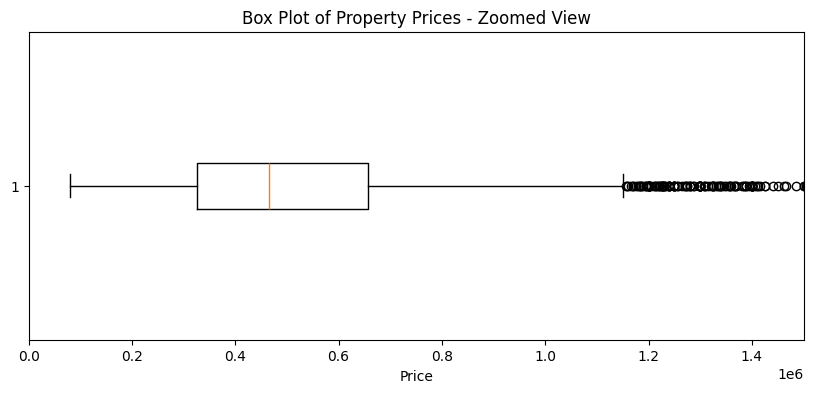

In [16]:
plt.figure(figsize=(10, 4))

plt.boxplot(df["price"], vert=False)

plt.xlim(0, 1500000)

plt.title("Box Plot of Property Prices - Zoomed View")
plt.xlabel("Price")

plt.show()

In [17]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

price_outliers = df[
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
]

print(f"Q1: ${Q1:,.2f}")
print(f"Q3: ${Q3:,.2f}")
print(f"IQR: ${IQR:,.2f}")
print(f"Upper Outlier Boundary: ${upper_bound:,.2f}")
print(f"Lower Outlier Boundary: ${lower_bound:,.2f}")
print(f"Number of Price Outliers: {len(price_outliers)}")
print(f"Percentage of Price Outliers: {len(price_outliers)/len(df)*100:.2f}%")

Q1: $326,500.00
Q3: $657,000.00
IQR: $330,500.00
Upper Outlier Boundary: $1,152,750.00
Lower Outlier Boundary: $-169,250.00
Number of Price Outliers: 235
Percentage of Price Outliers: 5.18%


In [18]:
df.nlargest(10, "price")[
    [
        "price",
        "sqft_living",
        "bedrooms",
        "bathrooms",
        "waterfront",
        "view",
        "condition",
        "city"
    ]
]

,price,sqft_living,bedrooms,bathrooms,waterfront,view,condition,city
2286,7062500.0,10040,5.0,4.50,1,2,3,Bellevue
2653,4668000.0,9640,5.0,6.75,1,4,3,Mercer Island
2760,4489000.0,6430,4.0,3.00,0,0,3,Bellevue
3727,3800000.0,7050,5.0,5.50,0,2,4,Clyde Hill
1637,3710000.0,5550,4.0,3.50,0,2,4,Medina
252,3200000.0,6210,7.0,4.50,0,2,5,Seattle
1567,3100000.0,6980,6.0,4.25,0,4,4,Mercer Island
2771,3000000.0,4850,4.0,4.25,1,4,5,Kirkland
2328,2888000.0,8670,5.0,6.25,0,4,3,Seattle
1571,2750000.0,4430,4.0,3.25,0,0,3,Medina


In [19]:
percentiles = df["price"].quantile([
    0.10,
    0.25,
    0.50,
    0.75,
    0.90,
    0.95
])

percentiles

0.10     245100.0
0.25     326500.0
0.50     465000.0
0.75     657000.0
0.90     900000.0
0.95    1180000.0
Name: price, dtype: float64

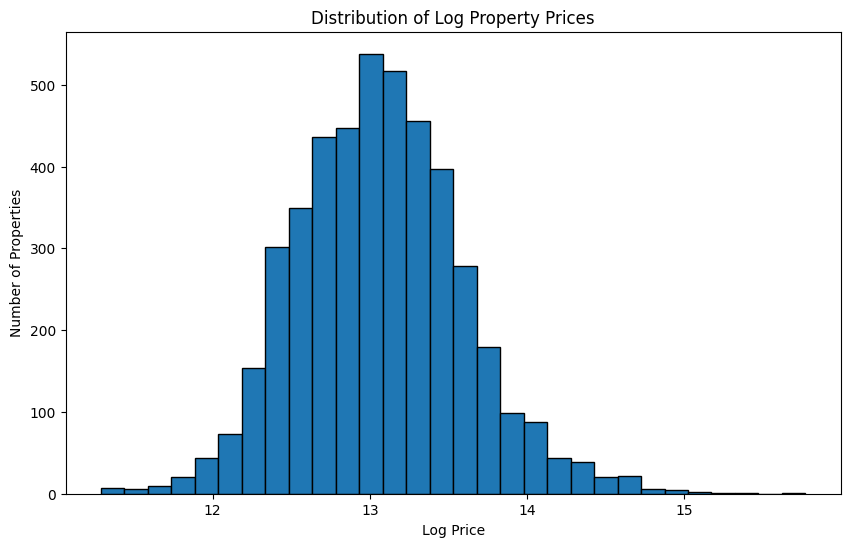

In [20]:
import numpy as np

plt.figure(figsize=(10, 6))

plt.hist(np.log1p(df["price"]), bins=30, edgecolor="black")

plt.title("Distribution of Log Property Prices")
plt.xlabel("Log Price")
plt.ylabel("Number of Properties")

plt.show()

#Explore Individual Feature Distributions

In [21]:
df["sqft_living"].describe()


count     4541.000000
mean      2131.238053
std        954.280247
min        370.000000
25%       1460.000000
50%       1970.000000
75%       2610.000000
max      13540.000000
Name: sqft_living, dtype: float64

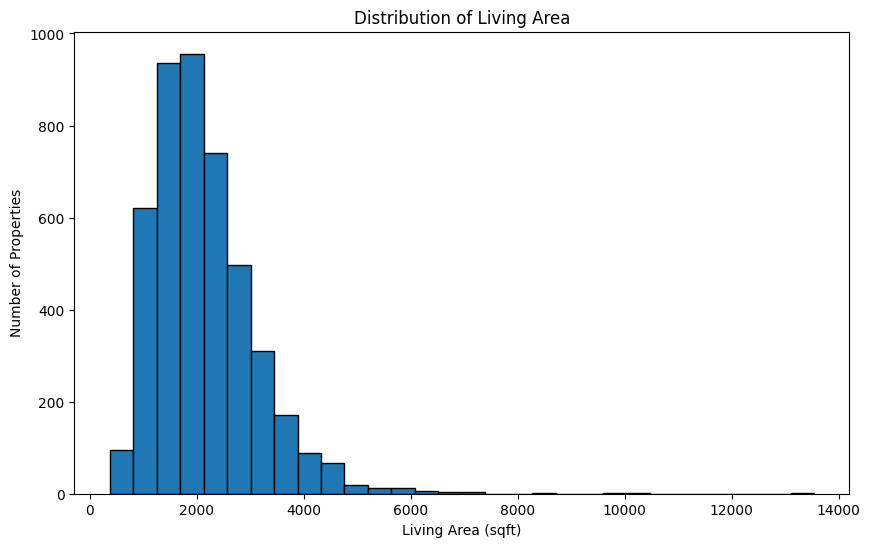

In [22]:
plt.figure(figsize=(10,6))

plt.hist(df["sqft_living"], bins=30, edgecolor="black")

plt.title("Distribution of Living Area")
plt.xlabel("Living Area (sqft)")
plt.ylabel("Number of Properties")

plt.show()

In [23]:
size_features = ["sqft_lot", "sqft_above", "sqft_basement"]

df[size_features].describe()

,sqft_lot,sqft_above,sqft_basement
count,4.541000e+03,4541.000000,4541.000000
mean,1.483941e+04,1821.369082,309.868972
std,3.600213e+04,853.126231,461.660624
min,6.380000e+02,370.000000,0.000000
25%,5.000000e+03,1190.000000,0.000000
50%,7.679000e+03,1590.000000,0.000000
75%,1.096000e+04,2300.000000,600.000000
max,1.074218e+06,9410.000000,4820.000000


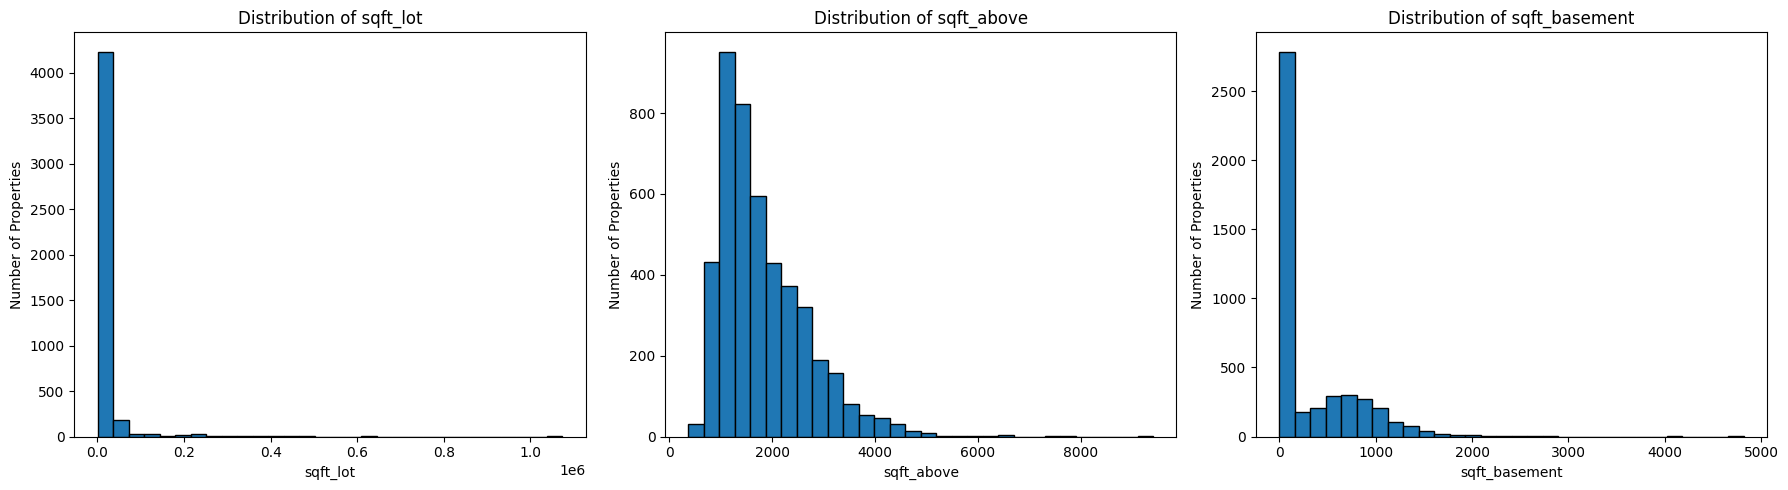

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for feature, ax in zip(size_features, axes):
    ax.hist(df[feature], bins=30, edgecolor="black")
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Properties")

plt.tight_layout()
plt.show()

In [25]:
room_features = ["bedrooms", "bathrooms", "floors"]

df[room_features].describe()

,bedrooms,bathrooms,floors
count,4541.000000,4541.000000,4541.000000
mean,3.395728,2.156133,1.512002
std,0.902014,0.775013,0.537697
min,1.000000,0.750000,1.000000
25%,3.000000,1.750000,1.000000
50%,3.000000,2.250000,1.500000
75%,4.000000,2.500000,2.000000
max,9.000000,8.000000,3.500000


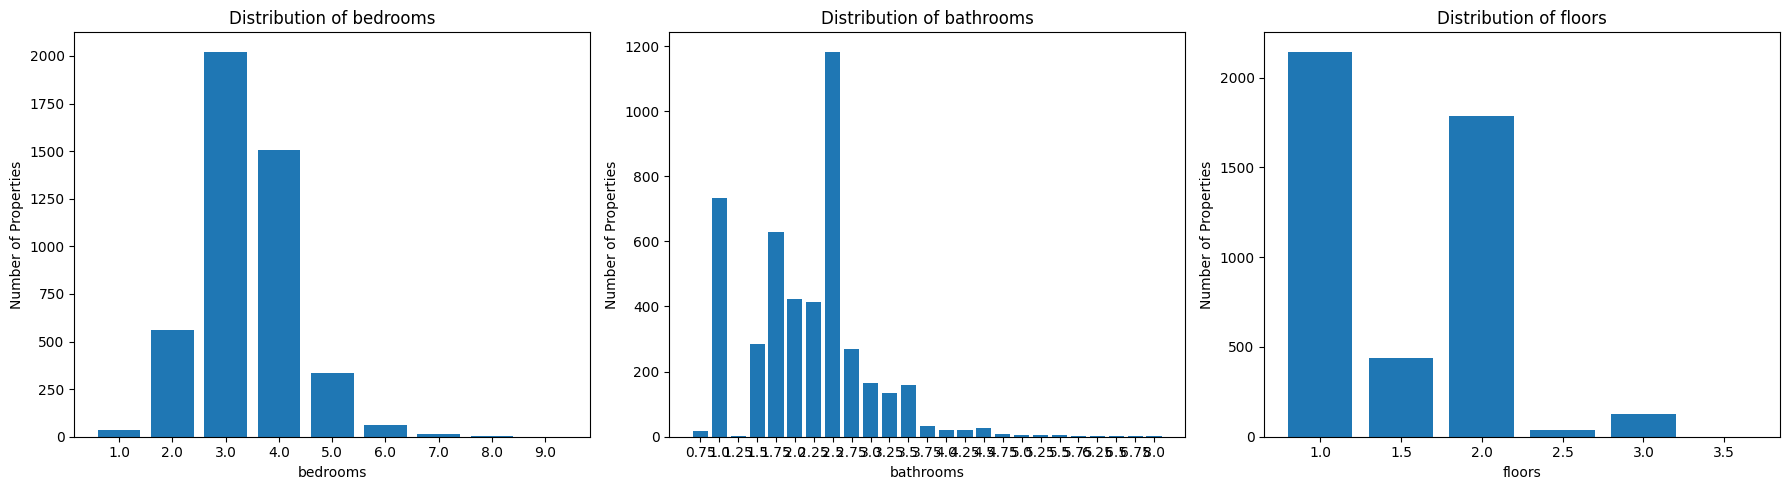

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for feature, ax in zip(room_features, axes):

    counts = df[feature].value_counts().sort_index()

    ax.bar(counts.index.astype(str), counts.values)

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Properties")

plt.tight_layout()
plt.show()

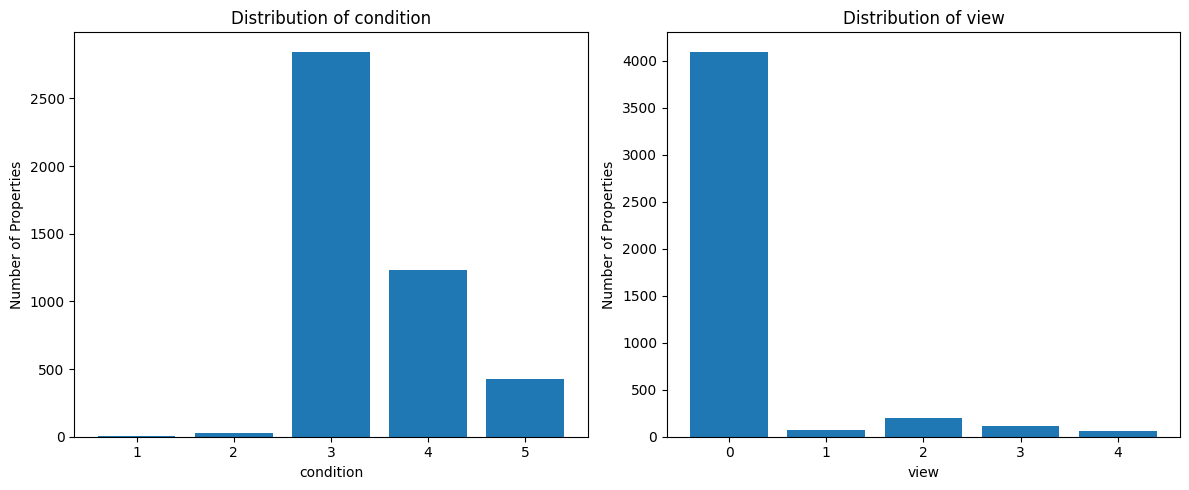

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

features = ["condition", "view"]

for feature, ax in zip(features, axes):

    counts = df[feature].value_counts().sort_index()

    ax.bar(counts.index.astype(str), counts.values)

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Properties")

plt.tight_layout()
plt.show()

In [28]:
binary_features = [
    "waterfront",
    "has_basement",
    "was_renovated"
]

percentages = df[binary_features].mean() * 100

percentages

waterfront        0.660647
has_basement     40.277472
was_renovated    40.475666
dtype: float64

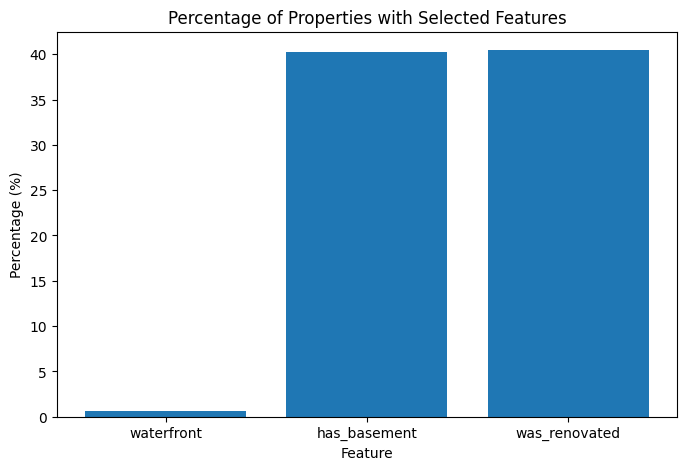

In [29]:
plt.figure(figsize=(8, 5))

plt.bar(percentages.index, percentages.values)

plt.title("Percentage of Properties with Selected Features")
plt.ylabel("Percentage (%)")
plt.xlabel("Feature")

plt.show()

In [30]:
df["house_age"].describe()

count    4541.000000
mean       43.187404
std        29.770049
min         0.000000
25%        17.000000
50%        38.000000
75%        63.000000
max       114.000000
Name: house_age, dtype: float64

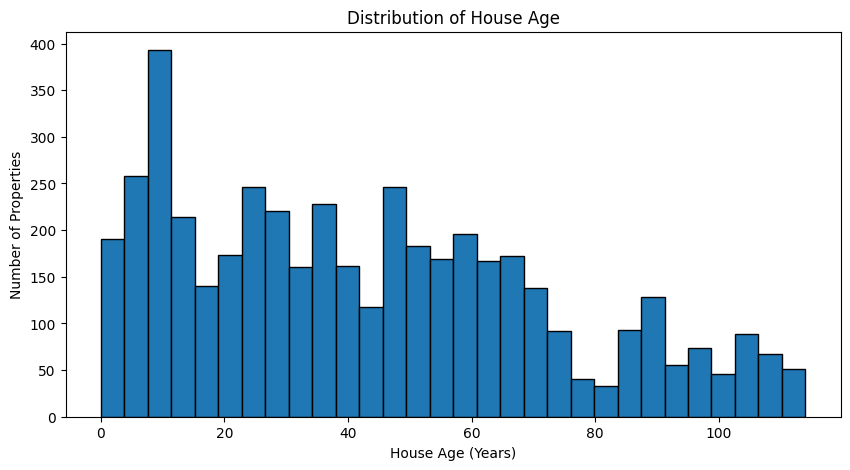

In [31]:
plt.figure(figsize=(10, 5))

plt.hist(df["house_age"], bins=30, edgecolor="black")

plt.title("Distribution of House Age")
plt.xlabel("House Age (Years)")
plt.ylabel("Number of Properties")

plt.show()

#Measure How Features Relate to Price

In [32]:
size_price_features = [
    "sqft_living",
    "sqft_lot",
    "sqft_above",
    "sqft_basement"
]

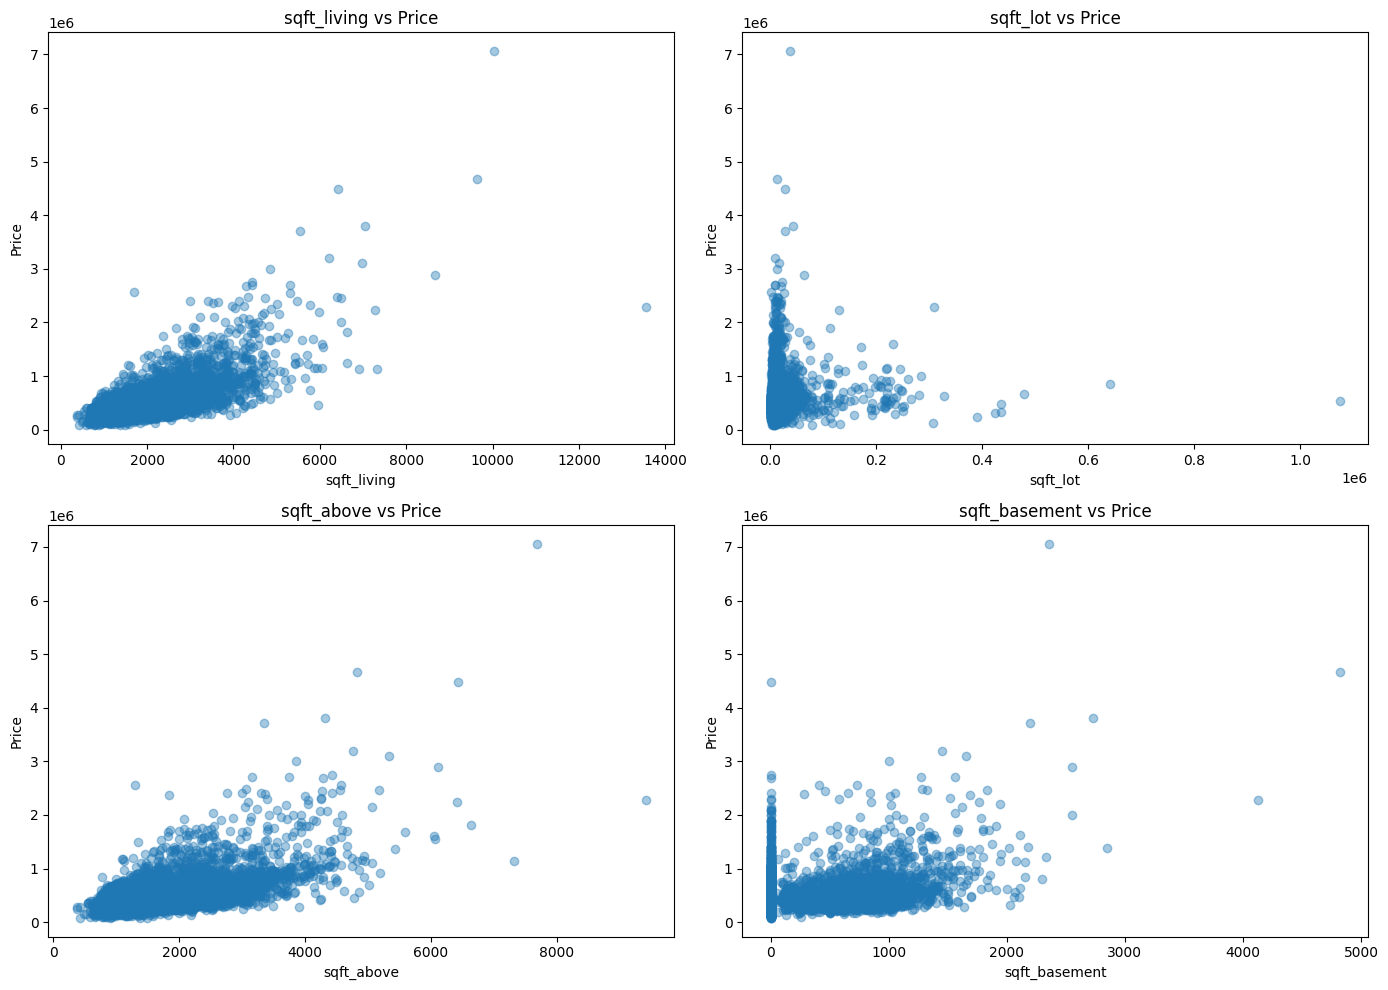

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(size_price_features, axes.flatten()):
    ax.scatter(df[feature], df["price"], alpha=0.4)
    ax.set_title(f"{feature} vs Price")
    ax.set_xlabel(feature)
    ax.set_ylabel("Price")

plt.tight_layout()
plt.show()

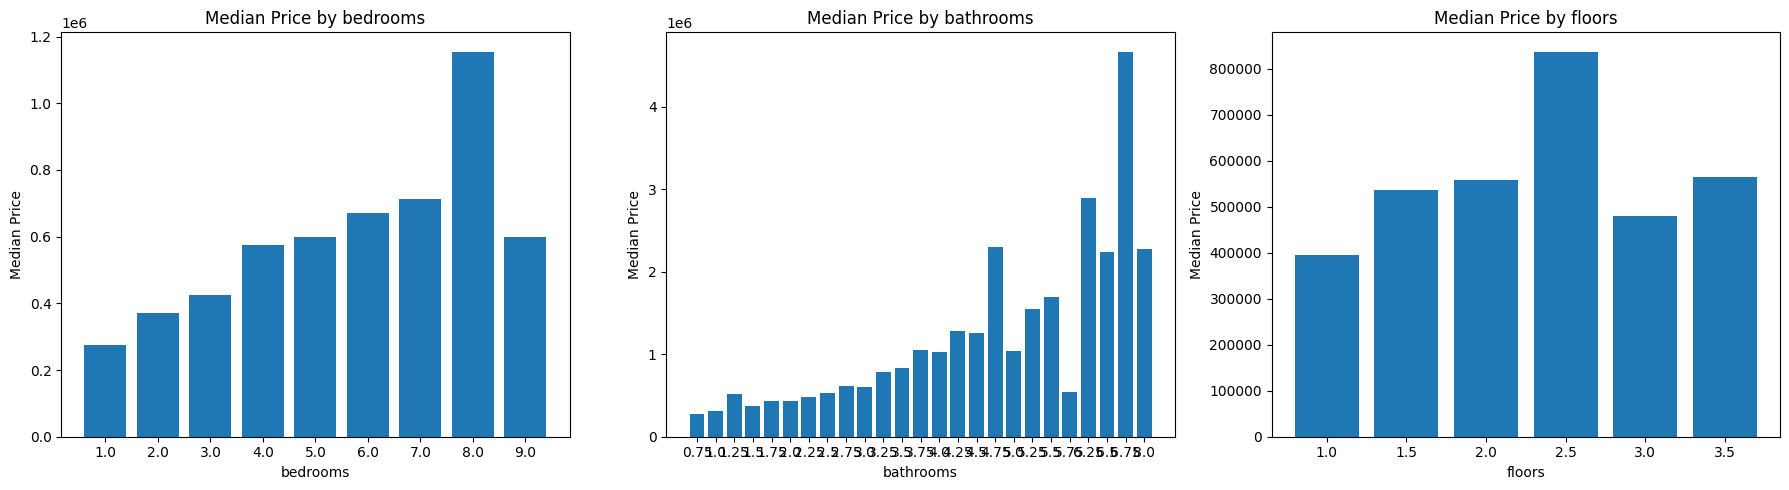

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for feature, ax in zip(room_features, axes):
    median_price = df.groupby(feature)["price"].median()

    ax.bar(median_price.index.astype(str), median_price.values)
    ax.set_title(f"Median Price by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Median Price")

plt.tight_layout()
plt.show()

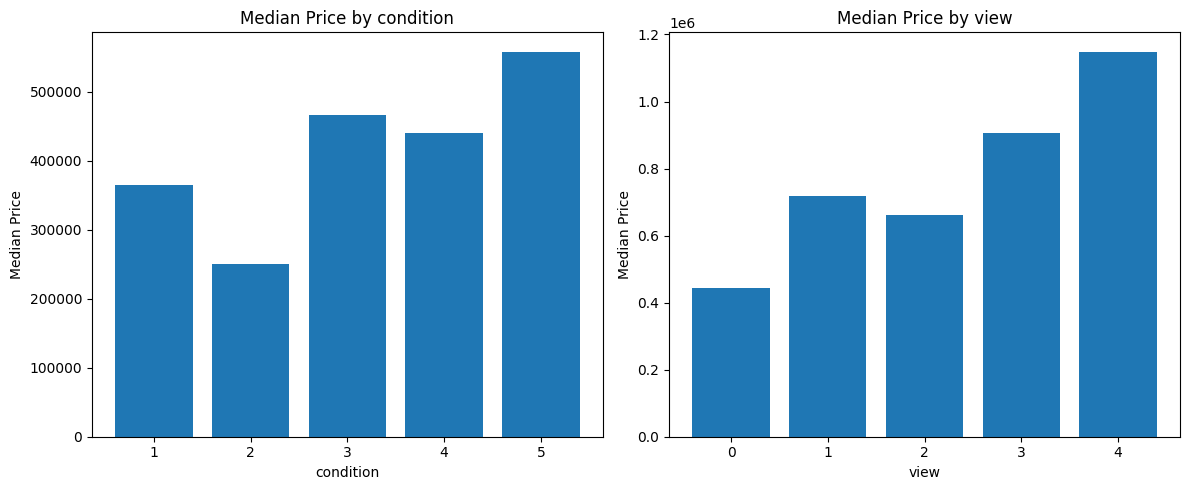

In [35]:
quality_features = ["condition", "view"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for feature, ax in zip(quality_features, axes):
    median_price = df.groupby(feature)["price"].median()

    ax.bar(median_price.index.astype(str), median_price.values)
    ax.set_title(f"Median Price by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Median Price")

plt.tight_layout()
plt.show()

In [36]:
binary_features = [
    "waterfront",
    "has_basement",
    "was_renovated"
]

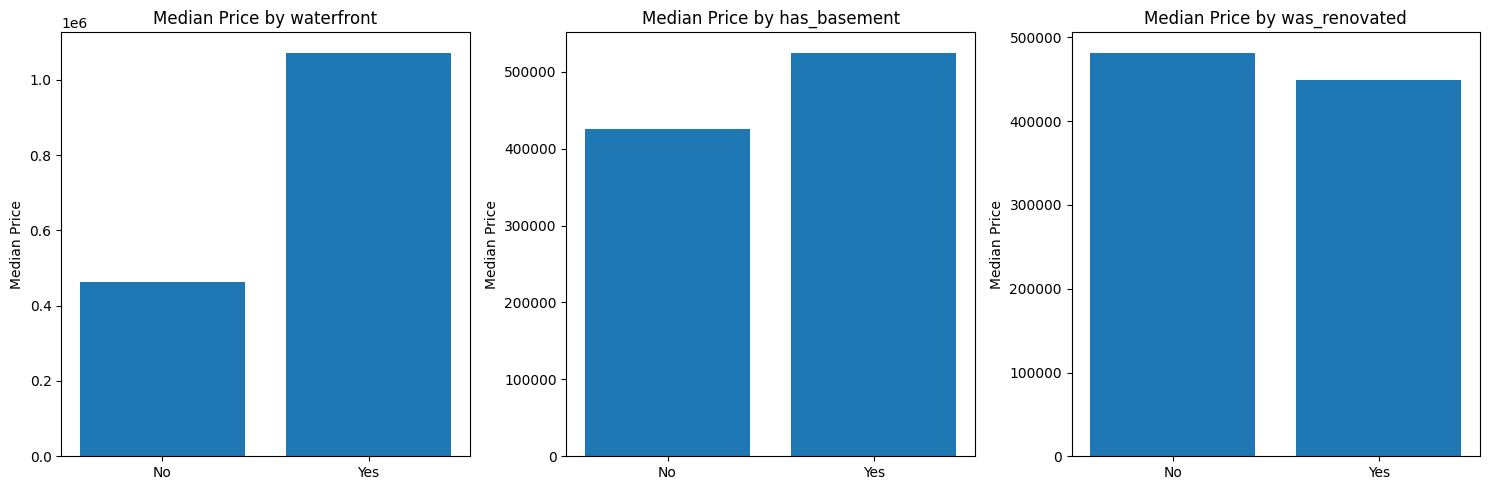

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for feature, ax in zip(binary_features, axes):
    median_price = df.groupby(feature)["price"].median()

    ax.bar(["No", "Yes"], median_price.values)

    ax.set_title(f"Median Price by {feature}")
    ax.set_ylabel("Median Price")

plt.tight_layout()
plt.show()

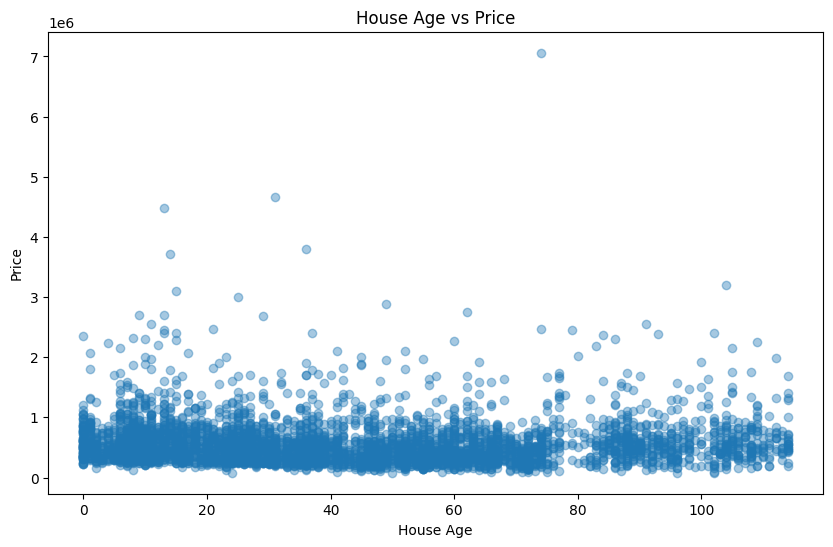

In [38]:
plt.figure(figsize=(10, 6))

plt.scatter(df["house_age"], df["price"], alpha=0.4)

plt.title("House Age vs Price")
plt.xlabel("House Age")
plt.ylabel("Price")

plt.show()

In [39]:
df[["house_age", "price"]].corr()

,house_age,price
house_age,1.000000,-0.025088
price,-0.025088,1.000000


# Rank the Strongest Price Relationships

In [40]:
corr_features = [
    "price",
    "bedrooms",
    "bathrooms",
    "sqft_living",
    "sqft_lot",
    "floors",
    "waterfront",
    "view",
    "condition",
    "sqft_above",
    "sqft_basement",
    "house_age",
    "has_basement",
    "was_renovated"
]

In [41]:
corr_matrix = df[corr_features].corr()

corr_matrix

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,sqft_above,sqft_basement,house_age,has_basement,was_renovated
price,1.000000,0.337026,0.531206,0.703476,0.083227,0.258239,0.233185,0.382013,0.053394,0.602084,0.341505,-0.025088,0.178232,-0.043677
bedrooms,0.337026,1.000000,0.545698,0.601280,0.071561,0.180265,-0.005642,0.116041,0.020463,0.491659,0.334320,-0.143872,0.177335,-0.061358
bathrooms,0.531206,0.545698,1.000000,0.761416,0.109645,0.493674,0.063373,0.205936,-0.124071,0.692123,0.294884,-0.467205,0.160893,-0.216802
sqft_living,0.703476,0.601280,0.761416,1.000000,0.213675,0.342111,0.108163,0.307776,-0.064292,0.875388,0.449386,-0.286626,0.201860,-0.123587
sqft_lot,0.083227,0.071561,0.109645,0.213675,1.000000,0.004337,0.017399,0.072909,0.000926,0.219522,0.036012,-0.049161,-0.027021,-0.021428
floors,0.258239,0.180265,0.493674,0.342111,0.004337,1.000000,0.015876,0.028525,-0.275714,0.521249,-0.256079,-0.468279,-0.273885,-0.237041
waterfront,0.233185,-0.005642,0.063373,0.108163,0.017399,0.015876,1.000000,0.348370,0.006057,0.072777,0.089091,0.032088,0.027251,0.015824
view,0.382013,0.116041,0.205936,0.307776,0.072909,0.028525,0.348370,1.000000,0.062246,0.172987,0.316520,0.065374,0.201944,0.024497
condition,0.053394,0.020463,-0.124071,-0.064292,0.000926,-0.275714,0.006057,0.062246,1.000000,-0.178431,0.196837,0.400359,0.173833,-0.183531
sqft_above,0.602084,0.491659,0.692123,0.875388,0.219522,0.521249,0.072777,0.172987,-0.178431,1.000000,-0.038471,-0.407968,-0.216540,-0.162979


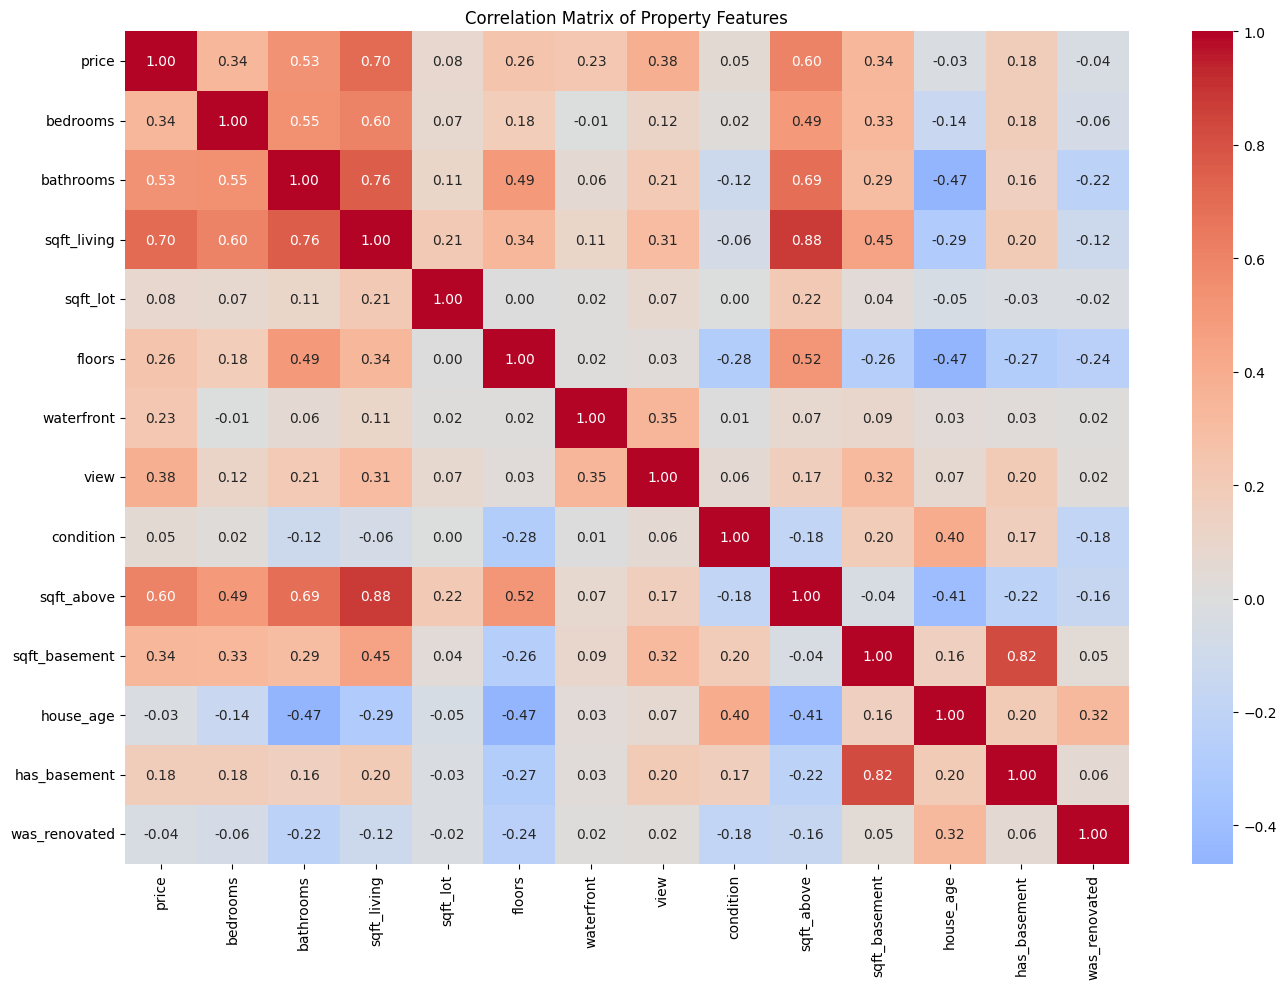

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of Property Features")
plt.tight_layout()
plt.show()

In [43]:
plt.figure(figsize=(10, 6))

price_correlations.sort_values().plot(kind="barh")

plt.title("Correlation of Property Features with Price")
plt.xlabel("Correlation with Price")
plt.ylabel("Feature")

plt.axvline(0, linewidth=1)

plt.tight_layout()
plt.show()

NameError: name 'price_correlations' is not defined

<Figure size 1000x600 with 0 Axes>

In [ ]:
def correlation_strength(r):
    r_abs = abs(r)

    if r_abs >= 0.70:
        return "Strong"
    elif r_abs >= 0.40:
        return "Moderate"
    elif r_abs >= 0.20:
        return "Weak"
    else:
        return "Very Weak"

correlation_summary = price_correlations.to_frame(
    name="Correlation"
)

correlation_summary["Strength"] = (
    correlation_summary["Correlation"]
    .apply(correlation_strength)
)

correlation_summary

# Location Analysis

In [ ]:
print("Number of cities:", df["city"].nunique())

In [ ]:
city_counts = df["city"].value_counts()

city_counts

In [ ]:
top_cities = (
    city_price[city_price["count"] >= 10]
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_cities.index[::-1],
    top_cities["median"][::-1]
)

plt.title("Top 10 Cities by Median Property Price")
plt.xlabel("Median Price")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [ ]:
city_price["count"] >= 10

In [ ]:
bottom_cities = (
    city_price[city_price["count"] >= 10]
    .sort_values("median")
    .head(10)
)

bottom_cities

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    bottom_cities.index,
    bottom_cities["median"]
)

plt.title("10 Cities with Lowest Median Property Price")
plt.xlabel("Median Price")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [ ]:
city_ppsf = (
    df.groupby("city")
      .agg(
          property_count=("price", "count"),
          median_price=("price", "median"),
          median_price_per_sqft=("price_per_sqft", "median"),
          median_living_area=("sqft_living", "median")
      )
      .sort_values("median_price_per_sqft", ascending=False)
)

city_ppsf.head(10)


In [ ]:
city_ppsf = (
    df.groupby("city")
      .agg(
          property_count=("price", "count"),
          median_price=("price", "median"),
          median_price_per_sqft=("price_per_sqft", "median"),
          median_living_area=("sqft_living", "median")
      )
      .sort_values("median_price_per_sqft", ascending=False)
)

city_ppsf.head(10)

In [ ]:
top_ppsf = (
    city_ppsf[city_ppsf["property_count"] >= 10]
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_ppsf.index[::-1],
    top_ppsf["median_price_per_sqft"][::-1]
)

plt.title("Top 10 Cities by Median Price per Sqft")
plt.xlabel("Median Price per Sqft")
plt.ylabel("City")

plt.tight_layout()
plt.show()

In [ ]:
city_comparison = (
    df.groupby("city")
      .agg(
          properties=("price", "count"),
          median_price=("price", "median"),
          median_living_area=("sqft_living", "median"),
          median_price_per_sqft=("price_per_sqft", "median")
      )
      .sort_values("median_price", ascending=False)
)

city_comparison

In [ ]:
reliable_zipcodes = zipcode_analysis[
    zipcode_analysis["properties"] >= 10
]

reliable_zipcodes.head(10)

In [ ]:
largest_cities = df["city"].value_counts().head(10).index

city_subset = df[df["city"].isin(largest_cities)]

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=city_subset,
    x="city",
    y="price",
    showfliers=False
)

plt.xticks(rotation=45)
plt.title("Property Price Distribution in Major Cities")
plt.xlabel("City")
plt.ylabel("Price")

plt.tight_layout()
plt.show()

#Price per Square Foot Analysis

In [ ]:
df["ratio_to_city_avg"].describe()

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df["ratio_to_city_avg"],
    bins=40,
    edgecolor="black"
)

plt.axvline(1, linestyle="--")

plt.title("Property Price per Sqft Relative to City Average")
plt.xlabel("Ratio to City Average")
plt.ylabel("Number of Properties")

plt.show()

In [ ]:
def market_position(ratio):
    if ratio < 0.8:
        return "Below City Average"
    elif ratio <= 1.2:
        return "Around City Average"
    else:
        return "Above City Average"

df["market_position"] = df["ratio_to_city_avg"].apply(market_position)

In [ ]:
below_market = (
    df[df["ratio_to_city_avg"] < 0.8]
    [
        [
            "city",
            "price",
            "sqft_living",
            "price_per_sqft",
            "city_avg_price_per_sqft",
            "ratio_to_city_avg",
            "condition",
            "view"
        ]
    ]
    .sort_values("ratio_to_city_avg")
)

below_market.head(10)

In [ ]:
above_market = (
    df[df["ratio_to_city_avg"] > 1.2]
    [
        [
            "city",
            "price",
            "sqft_living",
            "price_per_sqft",
            "city_avg_price_per_sqft",
            "ratio_to_city_avg",
            "condition",
            "view",
            "waterfront"
        ]
    ]
    .sort_values("ratio_to_city_avg", ascending=False)
)

above_market.head(10)

In [ ]:
feature_comparison = (
    df.groupby("market_position")
      .agg(
          median_living_area=("sqft_living", "median"),
          median_bathrooms=("bathrooms", "median"),
          median_condition=("condition", "median"),
          median_view=("view", "median"),
          waterfront_rate=("waterfront", "mean"),
          basement_rate=("has_basement", "mean"),
          renovation_rate=("was_renovated", "mean")
      )
)

feature_comparison

In [ ]:
condition_ppsf = (
    df.groupby("condition")["price_per_sqft"]
      .median()
)

condition_ppsf

In [ ]:
waterfront_ppsf = (
    df.groupby("waterfront")["price_per_sqft"]
      .median()
)

waterfront_ppsf

In [ ]:
renovated_ppsf = (
    df.groupby("was_renovated")["price_per_sqft"]
      .median()
)

renovated_ppsf

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["house_age"],
    df["price_per_sqft"],
    alpha=0.4
)

plt.title("House Age vs Price per Square Foot")
plt.xlabel("House Age")
plt.ylabel("Price per Square Foot")

plt.show()

In [ ]:
df[["house_age", "price_per_sqft"]].corr()

#Segment the Market


In [ ]:
q25 = df["price"].quantile(0.25)
q75 = df["price"].quantile(0.75)

print("25th percentile:", q25)
print("75th percentile:", q75)

In [ ]:
def price_segment(price):
    if price <= q25:
        return "Low-cost"
    elif price <= q75:
        return "Mid-market"
    else:
        return "Premium"

df["price_segment"] = df["price"].apply(price_segment)

In [ ]:
df["price_segment"].value_counts()

In [ ]:
area_comparison = (
    df.groupby("price_segment")["sqft_living"]
      .median()
)

area_comparison

In [ ]:
structure_comparison = (
    df.groupby("price_segment")
      .agg(
          median_bedrooms=("bedrooms", "median"),
          median_bathrooms=("bathrooms", "median"),
          median_floors=("floors", "median")
      )
)

structure_comparison

In [ ]:
binary_comparison = (
    df.groupby("price_segment")
      .agg(
          renovated_pct=("was_renovated", "mean"),
          waterfront_pct=("waterfront", "mean"),
          basement_pct=("has_basement", "mean")
      ) * 100
)

binary_comparison.round(2)

In [ ]:
quality_comparison = (
    df.groupby("price_segment")
      .agg(
          avg_view=("view", "mean"),
          median_condition=("condition", "median")
      )
)

quality_comparison.round(2)

In [ ]:
age_value_comparison = (
    df.groupby("price_segment")
      .agg(
          median_age=("house_age", "median"),
          median_price_per_sqft=("price_per_sqft", "median")
      )
)

age_value_comparison

# Investigate Outliers

In [ ]:
expensive_properties = (
    df.nlargest(10, "price")
    [
        [
            "price",
            "city",
            "sqft_living",
            "bedrooms",
            "bathrooms",
            "waterfront",
            "view",
            "condition",
            "price_per_sqft"
        ]
    ]
)

expensive_properties

In [ ]:
largest_properties = (
    df.nlargest(10, "sqft_living")
    [
        [
            "sqft_living",
            "price",
            "city",
            "bedrooms",
            "bathrooms",
            "floors",
            "waterfront",
            "view",
            "condition",
            "price_per_sqft"
        ]
    ]
)

largest_properties

In [ ]:
highest_ppsf = (
    df.nlargest(10, "price_per_sqft")
    [
        [
            "price_per_sqft",
            "price",
            "sqft_living",
            "city",
            "waterfront",
            "view",
            "condition",
            "was_renovated"
        ]
    ]
)

highest_ppsf

In [ ]:
lowest_ppsf = (
    df.nsmallest(10, "price_per_sqft")
    [
        [
            "price_per_sqft",
            "price",
            "sqft_living",
            "city",
            "waterfront",
            "view",
            "condition",
            "was_renovated"
        ]
    ]
)

lowest_ppsf

In [ ]:
Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

price_outliers = df[
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
]

print("Number of price outliers:", len(price_outliers))
print("Percentage:",
      round(len(price_outliers) / len(df) * 100, 2), "%")

#Time Analysis

In [ ]:
df["date"] = pd.to_datetime(df["date"])

In [ ]:
df["date"].dtype

In [ ]:
print("Start date:", df["date"].min())
print("End date:", df["date"].max())
print("Number of days:", (df["date"].max() - df["date"].min()).days)

In [ ]:
df["month"] = df["date"].dt.to_period("M")

In [ ]:
df["month"].value_counts().sort_index()

In [ ]:
monthly_sales = (
    df.groupby("month")
      .size()
      .reset_index(name="sales_count")
)

monthly_sales

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(
    monthly_sales["month"].astype(str),
    monthly_sales["sales_count"],
    marker="o"
)

plt.title("Number of Property Sales by Month")
plt.xlabel("Month")
plt.ylabel("Number of Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
monthly_price = (
    df.groupby("month")
      .agg(
          sales_count=("price", "count"),
          average_price=("price", "mean"),
          median_price=("price", "median")
      )
      .reset_index()
)

monthly_price

In [ ]:
plt.figure(figsize=(11,6))

plt.plot(
    monthly_price["month"].astype(str),
    monthly_price["average_price"],
    marker="o",
    label="Average Price"
)

plt.plot(
    monthly_price["month"].astype(str),
    monthly_price["median_price"],
    marker="o",
    label="Median Price"
)

plt.title("Property Prices Over Time")
plt.xlabel("Month")
plt.ylabel("Price")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
monthly_ppsf = (
    df.groupby("month")
      .agg(
          sales_count=("price_per_sqft", "count"),
          average_ppsf=("price_per_sqft", "mean"),
          median_ppsf=("price_per_sqft", "median")
      )
      .reset_index()
)

monthly_ppsf

In [ ]:
plt.figure(figsize=(11,6))

plt.plot(
    monthly_ppsf["month"].astype(str),
    monthly_ppsf["average_ppsf"],
    marker="o",
    label="Average Price/sqft"
)

plt.plot(
    monthly_ppsf["month"].astype(str),
    monthly_ppsf["median_ppsf"],
    marker="o",
    label="Median Price/sqft"
)

plt.title("Price per Square Foot Over Time")
plt.xlabel("Month")
plt.ylabel("Price per Square Foot")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
time_analysis = (
    df.groupby("month")
      .agg(
          sales_count=("price", "count"),
          average_price=("price", "mean"),
          median_price=("price", "median"),
          average_price_per_sqft=("price_per_sqft", "mean"),
          median_price_per_sqft=("price_per_sqft", "median")
      )
      .reset_index()
)

time_analysis.round(2)